# Metro view of interleaving maps

This notebook solves a small ceREEBerus ILP, displays its selected matrix entries, then draws the maps in both directions. The smoothed destination graph is the gray network; each colored strand is a source edge selected by the ILP's edge matrix. Outlined stations receive source vertices. This is a direct matrix view inspired by [MetroSets](https://arxiv.org/abs/2008.09367), the [atmospheric rivers study](https://www.sci.utah.edu/~beiwang/publications/AR_BeiWang_2024.pdf), and the [contour tree uncertainty study](https://www.sci.utah.edu/~beiwang/publications/Uncertainty_CT_BeiWang_2026.pdf).

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from cereeberus import Assignment
from cereeberus.data.ex_mappergraphs import line, torus
from cereeberus.draw.metro_maps import draw_interleaving_metro_maps, draw_metro_map

## Solve a reproducible example

The torus and line have different structure. At `n=2`, the ILP has a feasible solution.

In [2]:
F = torus(0, 1, 3, 4, delta=1, seed=17)
G = line(0, 4, seed=5)
assignment = Assignment(F, G, n=2)
feasible = assignment.optimize()
print(f"Feasible ILP at n={assignment.n}: {feasible}")
assert feasible, "Choose a feasible n before plotting."

Feasible ILP at n=2: True


## Inspect the selected rows

Each `1` in a matrix column selects the destination row. Compare these entries with the edge strands and vertex stations below.

In [3]:
def selected_entries(matrix):
    records = []
    for level in matrix.get_all_block_indices():
        block = matrix[level]
        for column, source in enumerate(block.cols):
            for row, target in enumerate(block.rows):
                if block.array[row, column] > 0.5:
                    records.append({"level": level, "source": source, "target": target})
    return pd.DataFrame(records)

for direction in ("phi", "psi"):
    for kind in ("V", "E"):
        print(f"{direction}, {kind}: source → target")
        display(selected_entries(getattr(assignment, direction)("0", kind)))

phi, V: source → target


,level,source,target
0,0,a,"(reeb_auto, 2)"
1,1,b,"(reeb_auto, 3)"
2,2,"(mapper_subd, 0)","(reeb_auto, 4)"
3,2,"(mapper_subd, 1)","(reeb_auto, 4)"
4,3,c,"(reeb_auto, 5)"
5,4,d,"(reeb_auto, 6)"


phi, E: source → target


,level,source,target
0,0,"(a, b, 0)","((reeb_auto, 2), (reeb_auto, 3), 0)"
1,1,"(b, (mapper_subd, 0), 0)","((reeb_auto, 3), (reeb_auto, 4), 0)"
2,1,"(b, (mapper_subd, 1), 0)","((reeb_auto, 3), (reeb_auto, 4), 0)"
3,2,"((mapper_subd, 0), c, 0)","((reeb_auto, 4), (reeb_auto, 5), 0)"
4,2,"((mapper_subd, 1), c, 0)","((reeb_auto, 4), (reeb_auto, 5), 0)"
5,3,"(c, d, 0)","((reeb_auto, 5), (reeb_auto, 6), 0)"


psi, V: source → target


,level,source,target
0,0,a,"(reeb_auto, 2)"
1,1,"(mapper_subd, 0)","(reeb_auto, 3)"
2,2,"(mapper_subd, 1)","(reeb_auto, 4)"
3,3,"(mapper_subd, 2)","(reeb_auto, 5)"
4,4,b,"(reeb_auto, 6)"


psi, E: source → target


,level,source,target
0,0,"(a, (mapper_subd, 0), 0)","((reeb_auto, 2), (reeb_auto, 3), 0)"
1,1,"((mapper_subd, 0), (mapper_subd, 1), 0)","((reeb_auto, 3), (reeb_auto, 4), 0)"
2,2,"((mapper_subd, 1), (mapper_subd, 2), 0)","((reeb_auto, 4), (reeb_auto, 5), 0)"
3,3,"((mapper_subd, 2), b, 0)","((reeb_auto, 5), (reeb_auto, 6), 0)"


## Both directions

Left: `phi: F → G^n`. Right: `psi: G → F^n`. Parallel colored strands reveal source edges sharing a destination edge. Gray segments receive no source edge.

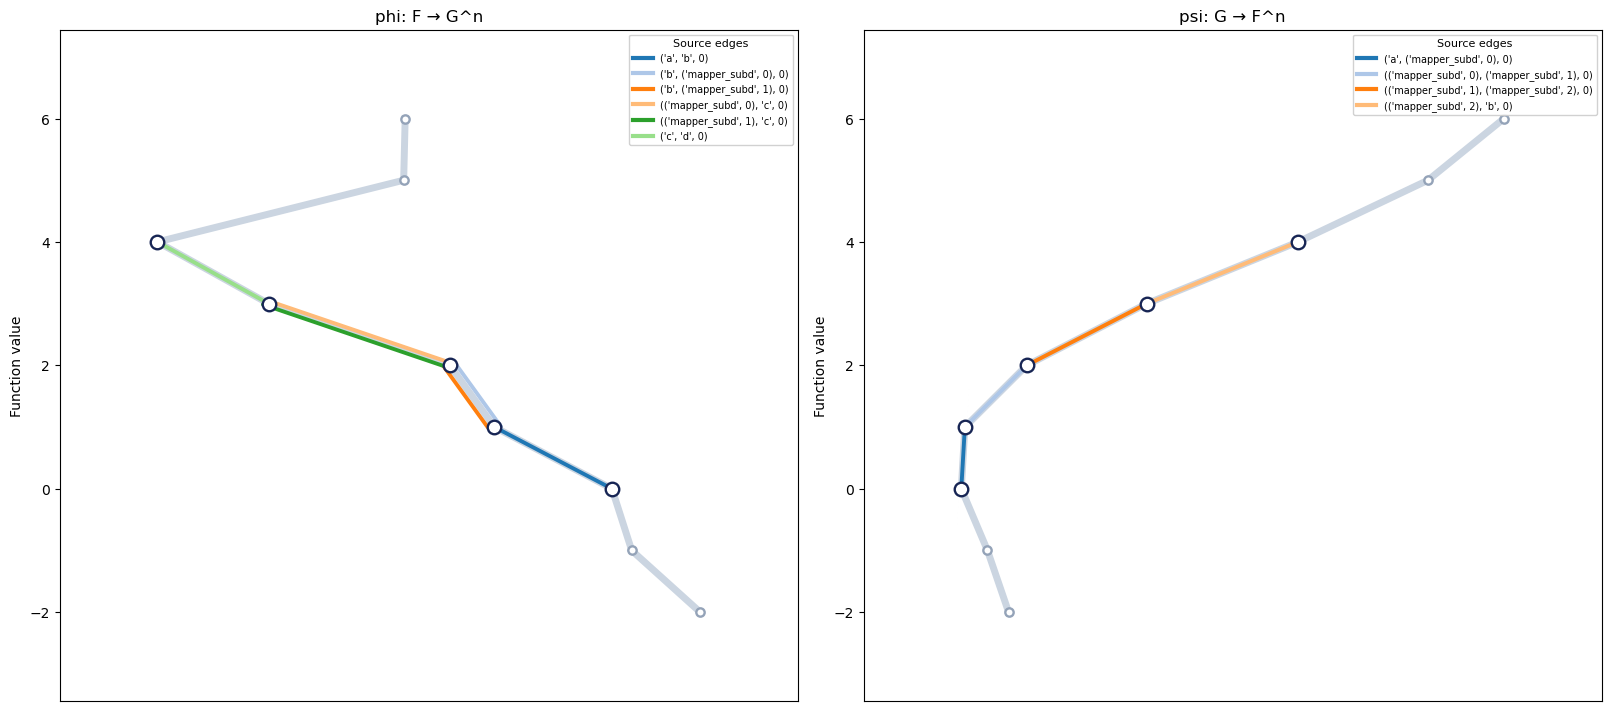

In [4]:
fig, axes = draw_interleaving_metro_maps(assignment, label_stations=False, max_legend=10)
plt.show()

## Stations and auxiliary maps

Station labels identify mapped source vertices. The auxiliary `key="n"` maps are `F^n → G^2n` and `G^n → F^2n`. Zero boundary columns in those maps produce no strand.

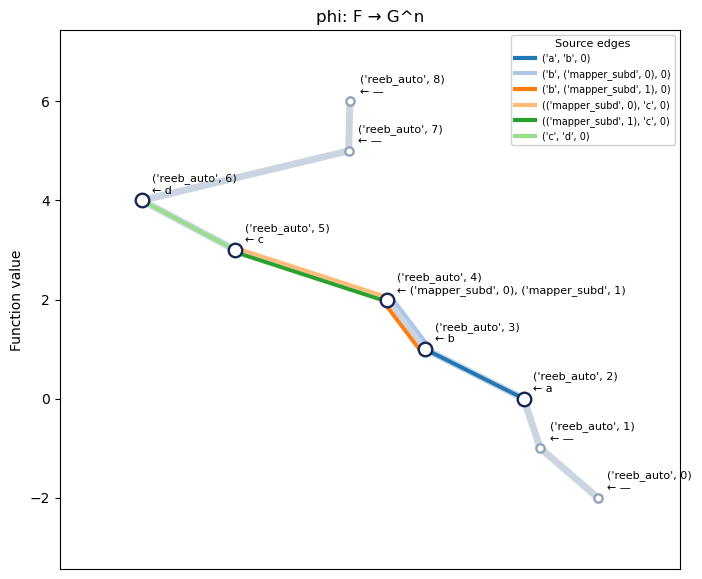

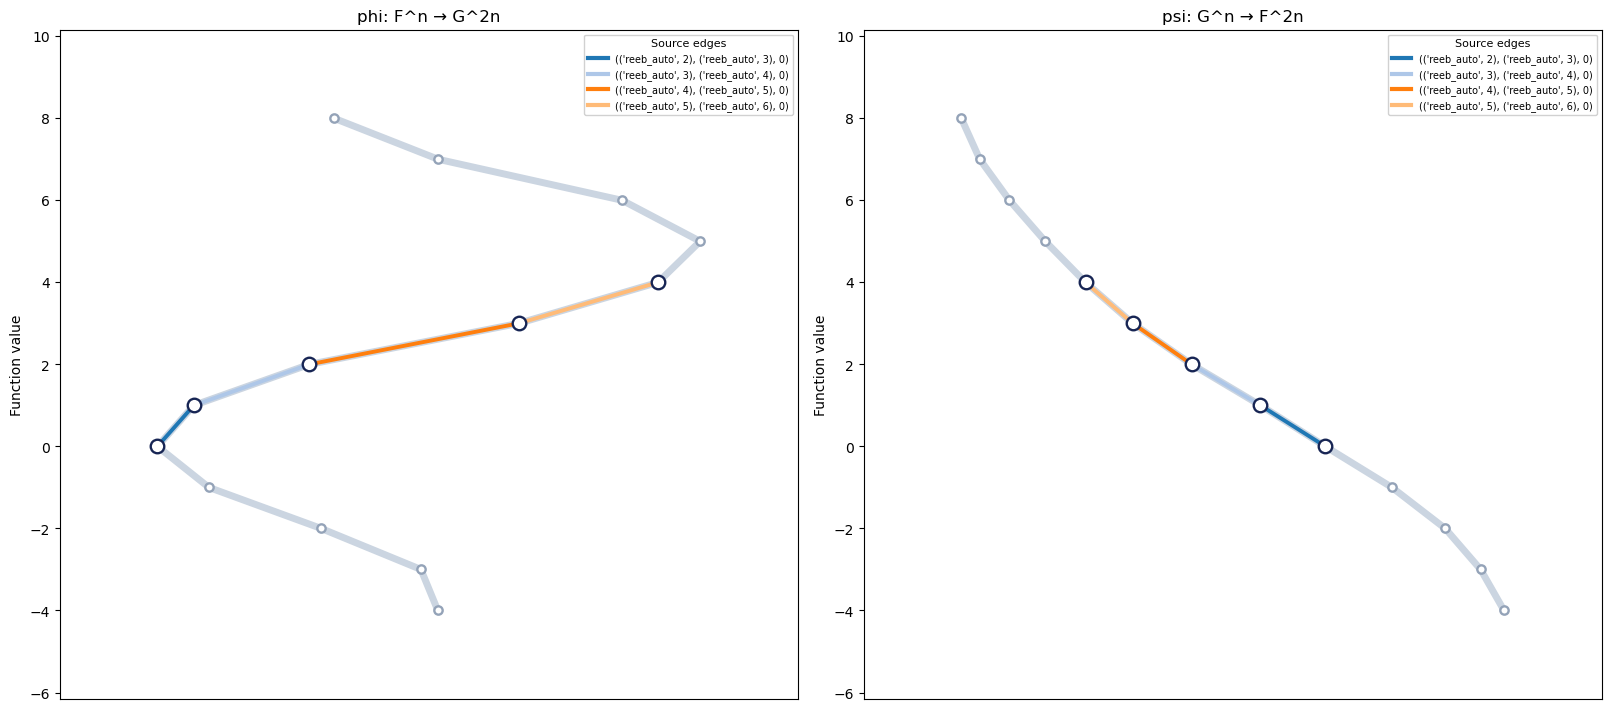

In [5]:
fig, ax = draw_metro_map(assignment, direction="phi", label_stations=True, max_legend=8)
plt.show()

fig, axes = draw_interleaving_metro_maps(assignment, key="n", label_stations=False, max_legend=10)
plt.show()

## Use your own ILP result

Replace `F`, `G`, and `n`, or pass a fitted `Interleave` object to `draw_interleaving_metro_maps`. The plotting functions read the ILP matrices without solving again. Strands represent individual source edges; full source paths and uncertainty values are not inferred.